In [1]:
from pathlib import Path
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [2]:
PROJECT_DIR = Path(
    "/Users/kakulrajput/Documents/Image_Detection"
)

DATASET_DIR = (
    PROJECT_DIR / "data" / "processed" / "image_dataset"
)

IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0

print("Dataset exists:", DATASET_DIR.exists())
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

Dataset exists: True
Image size: 224
Batch size: 16


In [3]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

print("Mean:", MEAN)
print("Std:", STD)

Mean: [0.485, 0.456, 0.406]
Std: [0.229, 0.224, 0.225]


In [4]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD ),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=MEAN,
        std=STD
    ),
])

In [5]:
train_dataset = datasets.ImageFolder(
    DATASET_DIR / "train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    DATASET_DIR / "val",
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    DATASET_DIR / "test",
    transform=eval_transform
)

print("Classes:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Classes: {'safe': 0, 'unsafe': 1}
Training images: 3609
Validation images: 771
Testing images: 773


In [6]:
expected_classes = {
    "safe": 0,
    "unsafe": 1,
}

assert train_dataset.class_to_idx == expected_classes
assert val_dataset.class_to_idx == expected_classes
assert test_dataset.class_to_idx == expected_classes

print("All class mappings are correct.")

All class mappings are correct.


In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 226
Validation batches: 49
Testing batches: 49


In [8]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels)

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Labels: tensor([1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0])


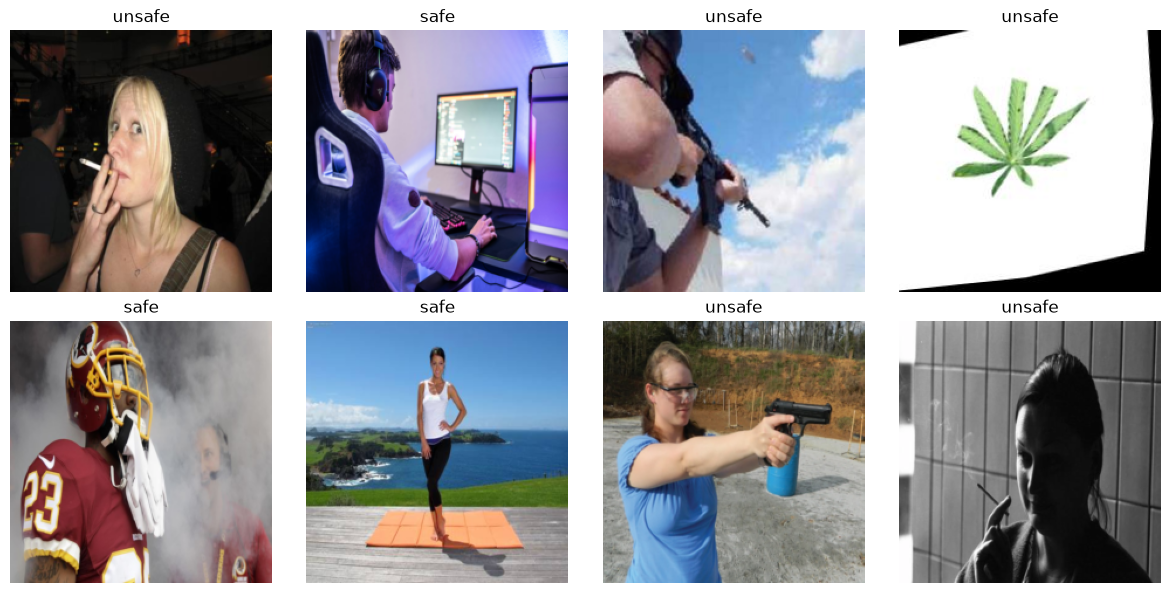

In [10]:
images, labels = next(iter(train_loader))

mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = images[i].cpu() * std + mean
    image = image.clamp(0, 1)

    image = image.permute(1, 2, 0)

    label = "unsafe" if labels[i].item() == 1 else "safe"

    ax.imshow(image)
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()